# Preprocessing Dataset Film untuk Sistem Rekomendasi MovieMatch

Notebook ini merapikan data film untuk proyek Sains Data MovieMatch, yang memakai sistem rekomendasi berbasis konten (TF-IDF), dan kemudian hasilnya berupa file `movies_clean_final.csv`.

Data diambil dari [The Movies Dataset](https://www.kaggle.com/datasets/rounakbanik/the-movies-dataset) di Kaggle, berisi sekitar 45.000 film dari TMDB sampai tahun 2017. File yang dipakai:

- `movies_metadata.csv`: data utama film
- `keywords.csv`: kata kunci cerita
- `credits.csv`: pemain dan kru, termasuk sutradara

File `links.csv` dan `ratings.csv` tidak dipakai, karena model mencari kemiripan dari isi film, bukan dari rating pengguna.

**Cara menjalankan:**

1. Unduh file ZIP dari Kaggle (nama file bebas).
2. Masukkan ZIP ke folder `data/raw/`
3. Jalankan semua sel (**Run all**). File hasil tersimpan di `data/processed/`.

**Susunan foldernya:**

```text
├── ...
├── data/
│   ├── raw/
│   │   └── the-movies-dataset.zip   ← taruh file ZIP di sini (nama file bebas)
│   └── processed/
│       └── movies_clean_final.csv   ← hasil akhir
└── sample_data
```

**Kolom pada file hasil:**

- `id`: nomor film di TMDB
- `title`: judul film
- `overview`: sinopsis, boleh kosong
- `genres_list`: daftar genre, dipisah `|`
- `keywords_list`: daftar kata kunci, dipisah `|`
- `director`: nama sutradara, dipisah `|` jika lebih dari satu
- `release_year`: tahun rilis, boleh kosong
- `vote_average`: rata-rata rating TMDB (0–10)
- `vote_count`: jumlah pemberi rating
- `poster_path`: alamat poster TMDB, contoh `/abc123.jpg`
- `runtime`: durasi dalam menit, boleh kosong
- `cast_list`: maksimal 6 pemeran utama, format `Nama::Peran`, dipisah `|`

Sembilan kolom pertama sama seperti versi sebelumnya. Tiga kolom baru (`poster_path`, `runtime`, `cast_list`) ada di paling kanan.


## 1. Pengaturan pustaka dan path data

Tahap ini menyiapkan pustaka dan lokasi file. File ZIP ditaruh di `data/raw/` (nama file bebas), dan hasilnya disimpan di `data/processed/movies_clean_final.csv`. Path dibuat otomatis, jadi notebook bisa dijalankan dari folder `notebooks/` maupun dari folder utama repo.

Urutan pencarian file ZIP:

- Jika `ZIP_PATH` diisi, file itu yang dipakai.
- Jika kosong, notebook mencari file `.zip` di `data/raw/`, lalu di folder kerja.
- Jika tetap tidak ada dan notebook berjalan di Colab, akan muncul tombol unggah.

Tahap ini juga menyiapkan fungsi `jumlah_teks_kosong` untuk menghitung sinopsis yang kosong, baik berupa NaN, teks kosong, maupun yang hanya berisi spasi.

In [1]:
from pathlib import Path
import ast
import os
import zipfile
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Menentukan folder utama repo agar path tetap benar saat notebook dijalankan dari folder notebooks/
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = ROOT_DIR / "data" / "raw"
EXTRACT_DIR = DATA_DIR / "extracted"
CSV_OUTPUT = ROOT_DIR / "data" / "processed" / "movies_clean_final.csv"
CSV_OUTPUT.parent.mkdir(parents=True, exist_ok=True)
ZIP_PATH = None  # contoh: DATA_DIR / "the-movies-dataset.zip"


def jumlah_teks_kosong(series):
    """Menghitung nilai yang NaN, string kosong, atau hanya spasi."""
    return int(series.fillna("").astype(str).str.strip().eq("").sum())


def temukan_zip(zip_path=ZIP_PATH):
    """Mencari file ZIP dataset di ZIP_PATH, folder data/, atau folder kerja."""
    if zip_path is not None:
        p = Path(zip_path)
        if not p.exists():
            raise FileNotFoundError(f"File ZIP tidak ditemukan: {p}")
        return p

    kandidat = []
    if DATA_DIR.is_dir():
        kandidat.extend(sorted(DATA_DIR.glob("*.zip")))
    kandidat.extend(sorted(Path(".").glob("*.zip")))

    unik = []
    sudah = set()
    for file_zip in kandidat:
        kunci = file_zip.resolve()
        if kunci not in sudah:
            sudah.add(kunci)
            unik.append(file_zip)

    if len(unik) == 1:
        return unik[0]
    if len(unik) > 1:
        print("Ditemukan lebih dari satu file ZIP:")
        for i, file_zip in enumerate(unik, 1):
            print(f"  {i}. {file_zip}")
        raise SystemExit(
            "Isi ZIP_PATH di sel pengaturan path dengan salah satu path di atas, "
            "lalu jalankan ulang sel."
        )
    return None


def path_csv(nama_file):
    """Menemukan file CSV hasil ekstraksi, termasuk jika ada folder di dalam ZIP."""
    langsung = EXTRACT_DIR / nama_file
    if langsung.exists():
        return langsung
    hits = list(EXTRACT_DIR.rglob(nama_file))
    if not hits:
        raise FileNotFoundError(
            f"{nama_file} tidak ditemukan di {EXTRACT_DIR}. "
            "Periksa apakah file ZIP-nya benar."
        )
    return hits[0]


DATA_DIR.mkdir(parents=True, exist_ok=True)
zip_file = temukan_zip()

if zip_file is None:
    try:
        from google.colab import files

        print("File ZIP belum ditemukan. Silakan unggah dataset (file .zip).")
        uploaded = files.upload()
        nama_zip = [nama for nama in uploaded if nama.lower().endswith(".zip")]
        if not nama_zip:
            raise FileNotFoundError("Tidak ada file .zip yang diunggah.")
        if len(nama_zip) > 1:
            print("Beberapa file ZIP diunggah; yang dipakai:", nama_zip[0])
        # Pindahkan ke data/ agar path-nya rapi dan bisa dipakai ulang.
        tujuan = DATA_DIR / Path(nama_zip[0]).name
        Path(nama_zip[0]).replace(tujuan)
        zip_file = tujuan
    except ImportError as exc:
        raise FileNotFoundError(
            "File ZIP tidak ditemukan. Letakkan file .zip di folder data/ "
            "atau di folder kerja, atau isi ZIP_PATH."
        ) from exc

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print(f"Dataset diekstrak dari : {zip_file}")
print(f"Folder tujuan          : {EXTRACT_DIR.resolve()}")


Dataset diekstrak dari : d:\Projek\sistem-rekomendasi-film\data\raw\The Movie Dataset.zip
Folder tujuan          : D:\Projek\sistem-rekomendasi-film\data\raw\extracted


## 2. Mengecek isi ZIP

Setelah ZIP diekstrak, tahap ini memastikan tiga file utama tersedia, yaitu `movies_metadata.csv`, `keywords.csv`, dan `credits.csv`. Ketiga file ini dipakai untuk menyusun CSV bersih.


In [2]:
file_csv = sorted(EXTRACT_DIR.rglob("*.csv"))
print(f"Jumlah file CSV: {len(file_csv)}")
for file in file_csv:
    print(file.relative_to(EXTRACT_DIR))


Jumlah file CSV: 7
credits.csv
keywords.csv
links.csv
links_small.csv
movies_metadata.csv
ratings.csv
ratings_small.csv


## 3. Membaca dataset

Tahap ini membaca tiga file utama. File `ratings.csv` tidak dibaca karena ukurannya sangat besar dan tidak dibutuhkan oleh model content-based yang dikerjakan.


In [3]:
df_movies = pd.read_csv(path_csv("movies_metadata.csv"), low_memory=False)
df_keywords = pd.read_csv(path_csv("keywords.csv"))
df_credits = pd.read_csv(path_csv("credits.csv"))

print("Semua dataset utama berhasil dibaca.")
print("Movies   :", df_movies.shape)
print("Keywords :", df_keywords.shape)
print("Credits  :", df_credits.shape)


Semua dataset utama berhasil dibaca.
Movies   : (45466, 24)
Keywords : (46419, 2)
Credits  : (45476, 3)


## 4. Inspeksi awal

Sebelum data digabungkan, tahap ini mengecek kondisi tiap tabel. Yang dicek adalah ukuran data, nama kolom, tipe data, jumlah nilai kosong, dan baris yang sama persis.

Untuk kolom `overview`, `isnull()` hanya menghitung nilai NaN. Sinopsis yang hanya berisi spasi belum ikut terhitung, jadi pengecekan lengkapnya dilakukan di tahap berikutnya.


In [4]:
datasets = {
    "Movies Metadata": df_movies,
    "Keywords": df_keywords,
    "Credits": df_credits,
}

for nama, df in datasets.items():
    print(f"\n===== {nama} =====")
    print("Jumlah baris :", df.shape[0])
    print("Jumlah kolom :", df.shape[1])
    print("Nama kolom   :", list(df.columns))

print("\n===== INFORMASI DATASET FILM =====")
df_movies.info()

print("\n===== JUMLAH NILAI KOSONG (Movies) =====")
print(df_movies.isnull().sum())

print("\n===== BARIS IDENTIK (duplikat seluruh kolom) =====")
for nama, df in datasets.items():
    print(f"{nama}: {df.duplicated().sum()}")



===== Movies Metadata =====
Jumlah baris : 45466
Jumlah kolom : 24
Nama kolom   : ['adult', 'belongs_to_collection', 'budget', 'genres', 'homepage', 'id', 'imdb_id', 'original_language', 'original_title', 'overview', 'popularity', 'poster_path', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'video', 'vote_average', 'vote_count']

===== Keywords =====
Jumlah baris : 46419
Jumlah kolom : 2
Nama kolom   : ['id', 'keywords']

===== Credits =====
Jumlah baris : 45476
Jumlah kolom : 3
Nama kolom   : ['cast', 'crew', 'id']

===== INFORMASI DATASET FILM =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45466 entries, 0 to 45465
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   adult                  45466 non-null  object 
 1   belongs_to_collection  4494 non-null   object 
 2   budget                 45466 

## 5. Menghitung jumlah overview kosong

Tahap ini menghitung film yang tidak punya sinopsis. Jika hanya NaN yang dihitung, hasilnya 954 film. Ada juga 5 film yang sinopsisnya hanya berisi spasi, jadi totalnya 954 + 5 = 959 film.

Pengecekan dengan `.isna()` saja tidak cukup, karena setelah NaN diganti teks kosong hasilnya menjadi 0, padahal sinopsisnya tetap tidak ada.

Film-film ini tidak dihapus, karena judul, genre, dan kata kuncinya masih berguna untuk model. NaN cukup diganti teks kosong agar proses TF-IDF tidak error.

In [5]:
nan_saja = int(df_movies["overview"].isna().sum())
kosong_semua = jumlah_teks_kosong(df_movies["overview"])
hanya_spasi = (
    (~df_movies["overview"].isna())
    & (df_movies["overview"].astype(str).str.strip() == "")
)

print("Overview NaN saja                    :", nan_saja)
print("Overview kosong/hanya spasi          :", kosong_semua)
print("Selisih (teks hanya spasi, bukan NaN):", kosong_semua - nan_saja)

print("\nFilm yang overview-nya hanya spasi:")
display(
    df_movies.loc[
        hanya_spasi,
        ["id", "title", "overview", "release_date"],
    ]
)


Overview NaN saja                    : 954
Overview kosong/hanya spasi          : 959
Selisih (teks hanya spasi, bukan NaN): 5

Film yang overview-nya hanya spasi:


,id,title,overview,release_date
4246,47596,Snow days,,1999-01-01
4538,49788,Slaves of New York,,1989-03-18
18171,46770,Sur,,1988-01-01
28408,47110,Afstiros katallilo,,2008-10-23
34919,43524,Iceland,,1942-09-21


## 6. Pemeriksaan ID

ID film dipakai untuk menggabungkan metadata, kata kunci, dan credits, jadi ID harus berupa angka, tidak dobel, dan cocok di ketiga tabel.

Masalah yang ditemukan:

- Beberapa ID di `movies_metadata` berisi tanggal, bukan angka. Kolom pada baris ini bergeser, jadi datanya tidak bisa dipakai.
- Beberapa ID muncul lebih dari sekali. Ada yang isinya sama persis, ada juga yang hanya berbeda di kolom seperti `popularity` atau `vote_count`.

In [6]:
print("===== PEMERIKSAAN ID =====")
for nama, df in datasets.items():
    id_numerik = pd.to_numeric(df["id"], errors="coerce")
    print(f"\n{nama}")
    print("  Jumlah baris        :", len(df))
    print("  ID unik             :", df["id"].nunique())
    print("  ID duplikat         :", int(df["id"].duplicated().sum()))
    print("  ID tidak valid      :", int(id_numerik.isna().sum()))

id_numerik_movies = pd.to_numeric(df_movies["id"], errors="coerce")
data_id_invalid = df_movies[id_numerik_movies.isna()]

print("\n===== BARIS DENGAN ID TIDAK VALID =====")
display(
    data_id_invalid[
        ["id", "title", "genres", "overview", "release_date", "runtime"]
    ]
)


===== PEMERIKSAAN ID =====

Movies Metadata
  Jumlah baris        : 45466
  ID unik             : 45436
  ID duplikat         : 30
  ID tidak valid      : 3

Keywords
  Jumlah baris        : 46419
  ID unik             : 45432
  ID duplikat         : 987
  ID tidak valid      : 0

Credits
  Jumlah baris        : 45476
  ID unik             : 45432
  ID duplikat         : 44
  ID tidak valid      : 0

===== BARIS DENGAN ID TIDAK VALID =====


,id,title,genres,overview,release_date,runtime
19730,1997-08-20,NaN,"[{'name': 'Carousel Productions', 'id': 11176}...",Released,1,NaN
29503,2012-09-29,NaN,"[{'name': 'Aniplex', 'id': 2883}, {'name': 'Go...",Released,12,NaN
35587,2014-01-01,NaN,"[{'name': 'Odyssey Media', 'id': 17161}, {'nam...",Released,22,NaN


## 7. Alasan penanganan data kosong dan duplikat

Cara pembersihan di tahap ini mengikuti hasil pemeriksaan sebelumnya.

**Data yang dihapus:**

- **ID tidak valid**, misalnya ID berisi tanggal seperti `1997-08-20`. Baris ini tidak punya judul dan kolomnya bergeser.
- **Baris yang sama persis**, karena hanya mengulang film yang sama.
- **ID dobel yang isinya sedikit berbeda.** Yang disimpan hanya baris dengan `vote_count` tertinggi, agar hasilnya selalu sama setiap kali dijalankan. Judul dan sinopsisnya sama, jadi tidak ada teks penting yang hilang.
- **Film tanpa judul** (3 film), karena judul dibutuhkan untuk menampilkan rekomendasi.
- **Film dewasa dan film yang belum rilis**, yaitu film dengan `adult=True` atau `status` selain `Released`. Film dengan `status` kosong tetap disimpan.

**Data yang tetap disimpan:**

- **Film tanpa sinopsis.** Sinopsis yang kosong atau hanya berisi spasi disimpan sebagai nilai kosong.
- **Film tanpa tahun rilis, genre, kata kunci, atau sutradara**, karena data lainnya masih bisa dipakai.

**Untuk keywords dan credits:** tipe ID disamakan, baris yang sama persis dihapus, dan setiap ID hanya punya satu baris. Jika ada data credits ganda untuk ID yang sama, data kru dan pemerannya digabung supaya nama sutradara dan pemeran tidak hilang.


In [7]:
# Cuplikan bukti: ID movies yang masih berulang setelah baris identik dibuang
movies_temp = df_movies.copy()
movies_temp["id"] = pd.to_numeric(movies_temp["id"], errors="coerce")
movies_temp = movies_temp.dropna(subset=["id"]).drop_duplicates()

dup_movies = movies_temp[movies_temp["id"].duplicated(keep=False)].sort_values("id")
print("Jumlah baris dengan ID berulang (setelah buang baris identik):", len(dup_movies))
print("Jumlah ID yang berulang :", dup_movies["id"].nunique())

variasi = movies_temp.groupby("id").nunique(dropna=False)
id_berbeda = variasi[(variasi > 1).any(axis=1)]
print("Jumlah ID yang atributnya tidak seluruhnya sama:", len(id_berbeda))
display(id_berbeda.head(15))


Jumlah baris dengan ID berulang (setelah buang baris identik): 26
Jumlah ID yang berulang : 13
Jumlah ID yang atributnya tidak seluruhnya sama: 13


,adult,belongs_to_collection,budget,genres,homepage,imdb_id,original_language,original_title,overview,popularity,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
id,,,,,,,,,,,,,,,,,,,,,
4912.0,1,1,1,1,1,1,1,1,1,2,...,1,1,1,1,1,1,1,1,1,1
10991.0,1,1,1,1,1,1,1,1,1,2,...,1,1,1,1,1,1,1,1,1,2
12600.0,1,1,1,1,1,1,1,1,1,2,...,1,1,1,1,1,1,1,1,1,1
13209.0,1,1,1,1,1,1,1,1,1,2,...,1,1,1,1,1,1,1,1,1,1
14788.0,1,1,1,1,1,1,1,1,1,2,...,1,1,1,1,1,1,1,1,1,1
15028.0,1,1,1,1,1,1,1,1,1,2,...,1,1,1,1,1,1,1,1,1,2
22649.0,1,1,1,1,1,1,1,1,1,2,...,1,1,1,1,1,1,1,1,1,1
69234.0,1,1,1,1,1,1,1,1,1,2,...,1,1,1,1,1,1,1,1,1,1
77221.0,1,1,1,1,1,1,1,1,1,2,...,1,1,1,1,1,1,1,1,1,1


## 8. Membersihkan movies, keywords, dan credits

Tahap ini membersihkan ketiga tabel. Pembersihan dilakukan pada salinan data, jadi tabel aslinya tetap ada untuk dibandingkan. Setelah tahap ini, setiap ID yang valid hanya punya satu baris di tiap tabel.


In [8]:
# ----- Movies -----
movies_clean = df_movies.copy()
movies_clean["id"] = pd.to_numeric(movies_clean["id"], errors="coerce")
movies_clean = movies_clean.dropna(subset=["id"])
movies_clean["id"] = movies_clean["id"].astype("int64")
movies_clean = movies_clean.drop_duplicates()
# Mengurutkan berdasarkan vote_count terbesar (pengurutan stabil)
# agar baris dengan jumlah vote tertinggi yang disimpan
movies_clean = movies_clean.sort_values(
    by="vote_count", ascending=False, kind="mergesort"
)
movies_clean = movies_clean.drop_duplicates(subset="id", keep="first")
# Mengembalikan urutan berdasarkan id setelah baris terpilih
movies_clean = movies_clean.sort_values(by="id").reset_index(drop=True)
# Isi NaN menjadi teks kosong; filmnya tetap disimpan
movies_clean["overview"] = movies_clean["overview"].fillna("")

print("===== MOVIES SETELAH CLEANING =====")
print("Jumlah baris   :", len(movies_clean))
print("ID unik        :", movies_clean["id"].nunique())
print("ID duplikat    :", int(movies_clean["id"].duplicated().sum()))
print(
    "Overview kosong (NaN/teks kosong/hanya spasi):",
    jumlah_teks_kosong(movies_clean["overview"]),
)

# ----- Keywords -----
keywords_clean = df_keywords.copy()
keywords_clean["id"] = pd.to_numeric(keywords_clean["id"], errors="coerce")
keywords_clean = keywords_clean.dropna(subset=["id"])
keywords_clean["id"] = keywords_clean["id"].astype("int64")
keywords_clean = keywords_clean.drop_duplicates()
keywords_clean = keywords_clean.drop_duplicates(subset=["id"], keep="first")

print("\n===== KEYWORDS SETELAH CLEANING =====")
print("Jumlah baris :", len(keywords_clean))
print("ID unik      :", keywords_clean["id"].nunique())
print("ID duplikat  :", int(keywords_clean["id"].duplicated().sum()))


# ----- Credits -----
def parse_list(data):
    """Mengubah teks yang menyerupai list Python menjadi list sungguhan."""
    try:
        hasil = ast.literal_eval(data)
        return hasil if isinstance(hasil, list) else []
    except (ValueError, SyntaxError, TypeError):
        return []


def gabung_crew(kumpulan):
    """Menggabungkan data kru dari beberapa baris dengan ID yang sama."""
    hasil = {}
    for crew in kumpulan:
        for orang in parse_list(crew):
            if isinstance(orang, dict):
                kunci = orang.get("credit_id") or str(orang)
                hasil[kunci] = orang
    return str(list(hasil.values()))


def gabung_cast(kumpulan):
    """Menggabungkan data pemeran dari beberapa baris dengan ID yang sama."""
    hasil = {}
    for cast in kumpulan:
        for orang in parse_list(cast):
            if isinstance(orang, dict):
                kunci = orang.get("credit_id") or str(orang)
                hasil[kunci] = orang
    return str(list(hasil.values()))


credits_temp = df_credits.copy()
credits_temp["id"] = pd.to_numeric(credits_temp["id"], errors="coerce")
credits_temp = credits_temp.dropna(subset=["id"])
credits_temp["id"] = credits_temp["id"].astype("int64")

print("\nMenggabungkan credits per ID (perlu waktu sejenak)...")
credits_clean = credits_temp.groupby("id", as_index=False).agg(
    {"cast": gabung_cast, "crew": gabung_crew}
)

print("===== CREDITS SETELAH CLEANING =====")
print("Jumlah baris :", len(credits_clean))
print("ID unik      :", credits_clean["id"].nunique())
print("ID duplikat  :", int(credits_clean["id"].duplicated().sum()))


===== MOVIES SETELAH CLEANING =====
Jumlah baris   : 45433
ID unik        : 45433
ID duplikat    : 0
Overview kosong (NaN/teks kosong/hanya spasi): 959

===== KEYWORDS SETELAH CLEANING =====
Jumlah baris : 45432
ID unik      : 45432
ID duplikat  : 0

Menggabungkan credits per ID (perlu waktu sejenak)...
===== CREDITS SETELAH CLEANING =====
Jumlah baris : 45432
ID unik      : 45432
ID duplikat  : 0


## 9. Ringkasan hasil cleaning dan kesesuaian ID

Tahap ini menunjukkan berapa baris yang berkurang di tiap tabel setelah dibersihkan. Selain itu, dihitung juga berapa film di `movies` yang tidak punya pasangan di `keywords` atau `credits`. Saat tabel digabungkan nanti, dipakai `how='left'` supaya film tanpa pasangan tetap tersimpan.


In [9]:
hasil_cleaning = pd.DataFrame(
    {
        "Dataset": ["Movies Metadata", "Keywords", "Credits"],
        "Sebelum Cleaning": [len(df_movies), len(df_keywords), len(df_credits)],
        "Sesudah Cleaning": [len(movies_clean), len(keywords_clean), len(credits_clean)],
    }
)
hasil_cleaning["Data Dihapus"] = (
    hasil_cleaning["Sebelum Cleaning"] - hasil_cleaning["Sesudah Cleaning"]
)
display(hasil_cleaning)

id_movies = set(movies_clean["id"])
id_keywords = set(keywords_clean["id"])
id_credits = set(credits_clean["id"])

print("ID Movies   :", len(id_movies))
print("ID Keywords :", len(id_keywords))
print("ID Credits  :", len(id_credits))
print("ID Movies tanpa Keywords :", len(id_movies - id_keywords))
print("ID Movies tanpa Credits  :", len(id_movies - id_credits))
print(
    "ID yang ada di ketiga dataset:",
    len(id_movies & id_keywords & id_credits),
)


,Dataset,Sebelum Cleaning,Sesudah Cleaning,Data Dihapus
0,Movies Metadata,45466,45433,33
1,Keywords,46419,45432,987
2,Credits,45476,45432,44


ID Movies   : 45433
ID Keywords : 45432
ID Credits  : 45432
ID Movies tanpa Keywords : 1
ID Movies tanpa Credits  : 1
ID yang ada di ketiga dataset: 45432


## 10. Menggabungkan metadata, kata kunci, dan credits

Tahap ini menggabungkan ketiga tabel berdasarkan `id`. Dipakai `how='left'` supaya semua film di `movies_clean` tetap ada, walaupun tidak punya data kata kunci atau credits. Film yang tidak punya pasangan akan bernilai kosong, lalu diubah menjadi daftar kosong di tahap berikutnya.

In [10]:
df_gabungan = movies_clean.merge(
    keywords_clean[["id", "keywords"]],
    on="id",
    how="left",
)
df_gabungan = df_gabungan.merge(
    credits_clean[["id", "cast", "crew"]],
    on="id",
    how="left",
)

print("Jumlah baris hasil merge :", len(df_gabungan))
print("Jumlah ID unik           :", df_gabungan["id"].nunique())
print("\nNilai kosong setelah merge:")
print(df_gabungan[["keywords", "cast", "crew"]].isna().sum())


Jumlah baris hasil merge : 45433
Jumlah ID unik           : 45433

Nilai kosong setelah merge:
keywords    1
cast        1
crew        1
dtype: int64


## 11. Mengekstrak genre, kata kunci, sutradara, pemeran, poster, dan durasi

Kolom `genres`, `keywords`, `crew`, dan `cast` di file asli masih berupa teks seperti daftar JSON, misalnya `[{'id': 18, 'name': 'Drama'}, ...]`. Tahap ini mengambil isinya menjadi kolom baru:

- `genres_list`: daftar nama genre
- `keywords_list`: daftar kata kunci
- `director`: nama kru dengan job Director. Nama yang berulang pada film yang sama dibuang.
- `cast_list`: maksimal 6 pemeran utama sesuai urutan `order`, dengan format `Nama::Peran` dan dipisah `|`. Jika perannya kosong, ditulis `Nama::`.
- `poster_path`: path poster dari metadata, disimpan seperti aslinya (termasuk garis miring di depan).
- `runtime`: durasi dalam menit. Nilai 0 dianggap tidak diketahui dan disimpan kosong.

Data yang kosong atau tidak bisa dibaca diubah menjadi daftar kosong agar tidak error. Saat disimpan ke CSV, daftar genre, kata kunci, dan pemeran ditulis sebagai teks yang dipisah tanda `|`.

In [11]:
def parse_obj_list(value):
    if pd.isna(value):
        return []
    try:
        hasil = ast.literal_eval(value)
        return hasil if isinstance(hasil, list) else []
    except (ValueError, SyntaxError, TypeError):
        return []


def extract_genres(value):
    data = parse_obj_list(value)
    return [
        item["name"]
        for item in data
        if isinstance(item, dict) and "name" in item
    ]


def extract_keywords(value):
    data = parse_obj_list(value)
    return [
        item["name"]
        for item in data
        if isinstance(item, dict) and "name" in item
    ]


def extract_director(value):
    data = parse_obj_list(value)
    nama = [
        item["name"]
        for item in data
        if isinstance(item, dict)
        and item.get("job") == "Director"
        and item.get("name")
    ]
    # Membuang nama sutradara yang berulang, dengan tetap mempertahankan urutan
    return list(dict.fromkeys(nama))


def bersihkan_teks_cast(teks):
    """Membuang spasi di pinggir, lalu mengganti '|' dan '::' agar pemisah tidak rusak."""
    if teks is None or (isinstance(teks, float) and pd.isna(teks)):
        return ""
    hasil = str(teks).strip()
    return hasil.replace("|", "/").replace("::", ":")


def extract_cast_list(value, batas=6):
    """Mengambil paling banyak 6 pemeran, diurutkan menurut field order."""
    data = parse_obj_list(value)
    pemeran = []
    for indeks, item in enumerate(data):
        if not isinstance(item, dict):
            continue
        nama = bersihkan_teks_cast(item.get("name"))
        if not nama:
            continue
        peran = bersihkan_teks_cast(item.get("character"))
        try:
            urutan = int(item.get("order"))
        except (TypeError, ValueError):
            urutan = 10**9
        pemeran.append((urutan, indeks, nama, peran))
    pemeran.sort(key=lambda x: (x[0], x[1]))
    # Peran kosong tetap memakai format Nama::
    return "|".join(f"{nama}::{peran}" for _, _, nama, peran in pemeran[:batas])


def rapikan_poster_path(value):
    """Menyimpan path poster apa adanya setelah spasi dibuang; yang kosong menjadi NaN."""
    if pd.isna(value):
        return pd.NA
    teks = str(value).strip()
    if teks == "" or teks.lower() in {"nan", "none"}:
        return pd.NA
    return teks


df_gabungan["genres_list"] = df_gabungan["genres"].apply(extract_genres)
df_gabungan["keywords_list"] = df_gabungan["keywords"].apply(extract_keywords)
df_gabungan["director"] = df_gabungan["crew"].apply(extract_director)
df_gabungan["cast_list"] = df_gabungan["cast"].apply(extract_cast_list)
df_gabungan["poster_path"] = df_gabungan["poster_path"].apply(rapikan_poster_path)
df_gabungan["runtime"] = pd.to_numeric(df_gabungan["runtime"], errors="coerce")
df_gabungan["runtime"] = df_gabungan["runtime"].mask(
    df_gabungan["runtime"].isna() | (df_gabungan["runtime"] == 0)
).astype("Int64")

display(
    df_gabungan[
        ["title", "genres_list", "keywords_list", "director", "cast_list", "poster_path", "runtime"]
    ].head(10)
)


,title,genres_list,keywords_list,director,cast_list,poster_path,runtime
0,Ariel,"[Drama, Crime]","[underdog, prison, factory worker, prisoner, h...",[Aki Kaurismäki],Turo Pajala::Taisto Olavi Kasurinen|Susanna Ha...,/gZCJZOn4l0Zj5hAxsMbxoS6CL0u.jpg,69
1,Shadows in Paradise,"[Drama, Comedy]","[salesclerk, helsinki, garbage, independent film]",[Aki Kaurismäki],Matti Pellonpää::Nikander|Kati Outinen::Ilona ...,/7ad4iku8cYBuB08g9yAU7tHJik5.jpg,76
2,Four Rooms,"[Crime, Comedy]","[hotel, new year's eve, witch, bet, hotel room...","[Allison Anders, Alexandre Rockwell, Robert Ro...",Tim Roth::Ted the Bellhop|Antonio Banderas::Ma...,/eQs5hh9rxrk1m4xHsIz1w11Ngqb.jpg,98
3,Judgment Night,"[Action, Thriller, Crime]","[chicago, drug dealer, boxing match, escape, o...",[Stephen Hopkins],Emilio Estevez::Frank Wyatt|Cuba Gooding Jr.::...,/lNXmgUrP6h1nD53gkFh4WDzT6RZ.jpg,110
4,Star Wars,"[Adventure, Action, Science Fiction]","[android, galaxy, hermit, death star, lightsab...",[George Lucas],Mark Hamill::Luke Skywalker|Harrison Ford::Han...,/btTdmkgIvOi0FFip1sPuZI2oQG6.jpg,121
5,Finding Nemo,"[Animation, Family]","[father son relationship, harbor, underwater, ...",[Andrew Stanton],Albert Brooks::Marlin (voice)|Ellen DeGeneres:...,/syPWyeeqzTQIxjIUaIFI7d0TyEY.jpg,100
6,Forrest Gump,"[Comedy, Drama, Romance]","[vietnam veteran, hippie, mentally disabled, r...",[Robert Zemeckis],Tom Hanks::Forrest Gump|Robin Wright::Jenny Cu...,/yE5d3BUhE8hCnkMUJOo1QDoOGNz.jpg,142
7,American Beauty,[Drama],"[male nudity, female nudity, adultery, parent ...",[Sam Mendes],Kevin Spacey::Lester Burnham|Annette Bening::C...,/or1MP8BZIAjqWYxPdPX724ydKar.jpg,122
8,Citizen Kane,"[Mystery, Drama]","[journalist, newspaper, florida, capitalist, b...",[Orson Welles],Orson Welles::Charles Foster Kane|Joseph Cotte...,/oFWvF7OJfT2ydAAatlnsgChV4FP.jpg,119
9,Dancer in the Dark,"[Drama, Crime, Music]","[individual, dancing, usa, robbery, factory wo...",[Lars von Trier],Björk::Selma Jezkova|Catherine Deneuve::Kathy|...,/7xizDTz4Yj4IYm2ud4f6EfEXe5H.jpg,140


## 12. Eksplorasi data: genre

Sebelum data disimpan, pola datanya dilihat terlebih dahulu, dimulai dari genre. Satu film bisa punya lebih dari satu genre, jadi total kemunculan genre lebih banyak dari jumlah film. Sel berikut menampilkan 10 genre yang paling sering muncul.


10 Genre Film Terbanyak:


,Genre,Jumlah Film
0,Drama,20244
2,Comedy,13176
4,Thriller,7619
9,Romance,6730
3,Action,6592
12,Horror,4671
1,Crime,4304
14,Documentary,3930
5,Adventure,3490
6,Science Fiction,3044


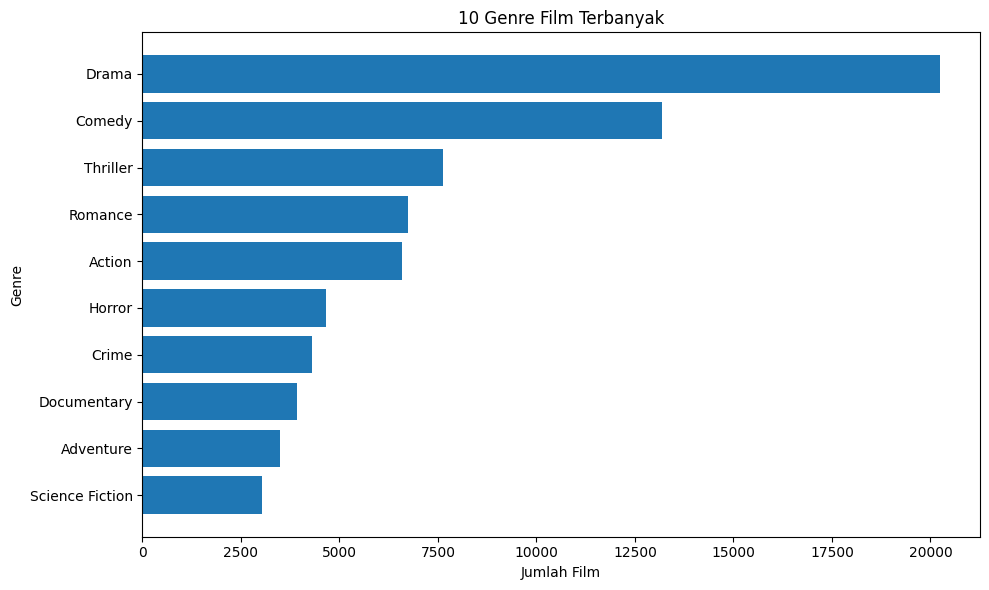

In [12]:
genre_counter = Counter(
    genre for genres in df_gabungan["genres_list"] for genre in genres
)
df_genre = (
    pd.DataFrame(genre_counter.items(), columns=["Genre", "Jumlah Film"])
    .sort_values(by="Jumlah Film", ascending=False)
)

print("10 Genre Film Terbanyak:")
display(df_genre.head(10))

plt.figure(figsize=(10, 6))
plt.barh(
    df_genre.head(10)["Genre"][::-1],
    df_genre.head(10)["Jumlah Film"][::-1],
)
plt.title("10 Genre Film Terbanyak")
plt.xlabel("Jumlah Film")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()


## 13. Eksplorasi data: tahun rilis

Tanggal rilis diubah ke format tanggal, lalu diambil tahunnya. Jika tanggalnya tidak valid, tahun rilis dibiarkan kosong, tetapi filmnya tetap disimpan. Grafik berikut menunjukkan jumlah film per tahun.


10 Tahun dengan Jumlah Film Terbanyak:


,Tahun,Jumlah Film
0,2014.0,1973
1,2015.0,1904
2,2013.0,1887
3,2012.0,1721
4,2011.0,1666
5,2016.0,1604
6,2009.0,1585
7,2010.0,1501
8,2008.0,1470
9,2007.0,1319


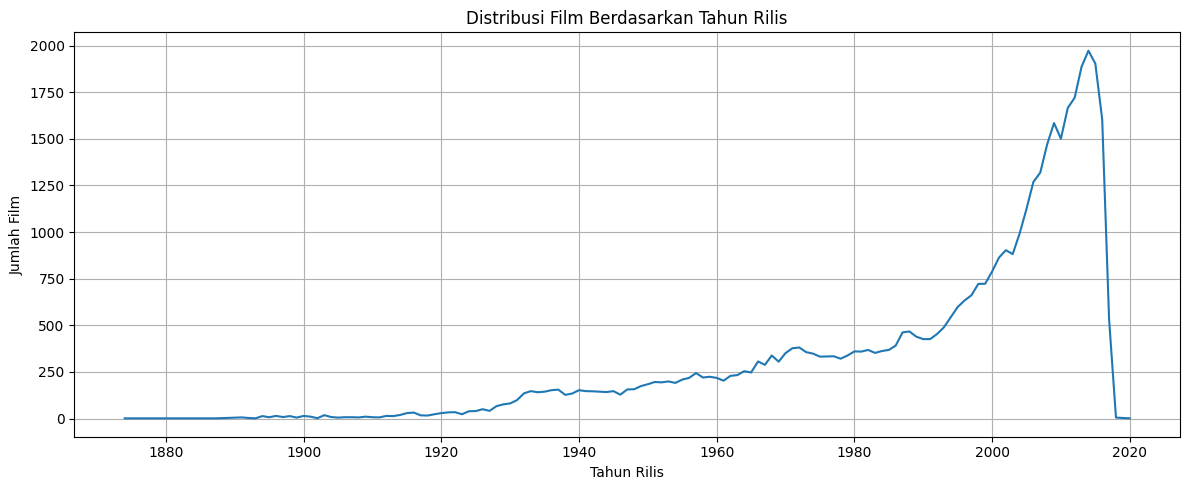

Jumlah tanggal rilis kosong/tidak valid: 87


In [13]:
df_gabungan["release_date"] = pd.to_datetime(
    df_gabungan["release_date"],
    errors="coerce",
)
df_gabungan["release_year"] = df_gabungan["release_date"].dt.year

df_tahun = df_gabungan["release_year"].value_counts().sort_index()

print("10 Tahun dengan Jumlah Film Terbanyak:")
display(
    df_tahun.sort_values(ascending=False)
    .head(10)
    .rename_axis("Tahun")
    .reset_index(name="Jumlah Film")
)

plt.figure(figsize=(12, 5))
plt.plot(df_tahun.index, df_tahun.values)
plt.title("Distribusi Film Berdasarkan Tahun Rilis")
plt.xlabel("Tahun Rilis")
plt.ylabel("Jumlah Film")
plt.grid(True)
plt.tight_layout()
plt.show()

print(
    "Jumlah tanggal rilis kosong/tidak valid:",
    int(df_gabungan["release_year"].isna().sum()),
)


## 14. Eksplorasi data: rating dan jumlah vote

Tahap ini melihat dua kolom angka:

- `vote_average`: rata-rata rating TMDB, skala 0 sampai 10
- `vote_count`: jumlah orang yang memberi rating

Kedua kolom ini membantu memahami kualitas data, walaupun model content-based terutama memakai teks, yaitu sinopsis, genre, kata kunci, dan sutradara.

Hal yang perlu diperhatikan:

- Banyak film hanya punya sedikit vote, jadi rata-rata `vote_count` jauh lebih besar dari nilai tengahnya.
- Rating 0 biasanya berarti film belum punya vote, bukan filmnya buruk. Pada tahap ini ada 2.896 film dengan 0 vote. Film ini tidak dihapus, dan di antarmuka sebaiknya ditampilkan sebagai "Belum ada rating", bukan "0,0".
- Rating 10 biasanya berasal dari sangat sedikit vote, jadi belum tentu film terbaik.


===== STATISTIK DESKRIPTIF vote_average =====
count    45430.000000
mean         5.618329
std          1.924139
min          0.000000
25%          5.000000
50%          6.000000
75%          6.800000
max         10.000000
Name: vote_average, dtype: float64

===== STATISTIK DESKRIPTIF vote_count =====
count    45430.000000
mean       109.936033
std        491.466335
min          0.000000
25%          3.000000
50%         10.000000
75%         34.000000
max      14075.000000
Name: vote_count, dtype: float64

Film dengan 0 vote             : 2896
Film dengan rating 0           : 2995
  di antaranya tanpa vote      : 2896
  tetapi punya vote            : 99
Korelasi Pearson rating vs jumlah vote: 0.12361104751160011


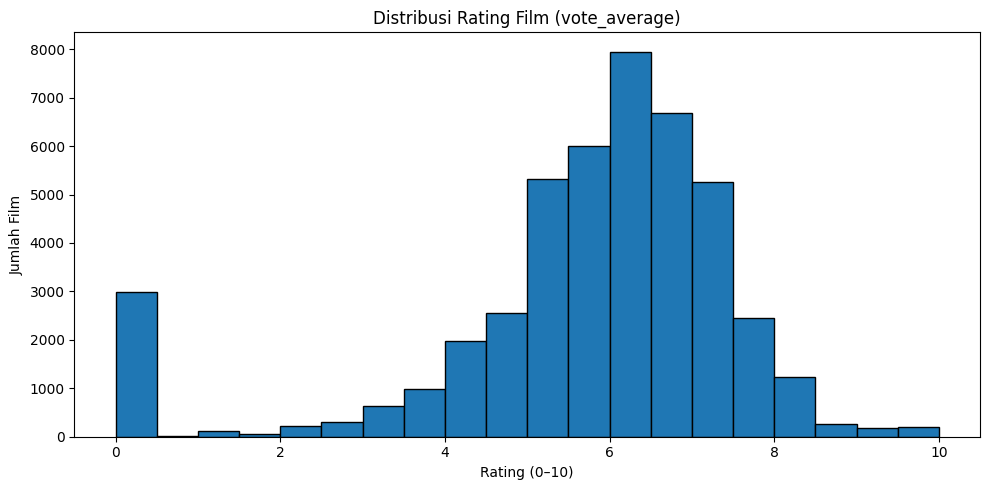

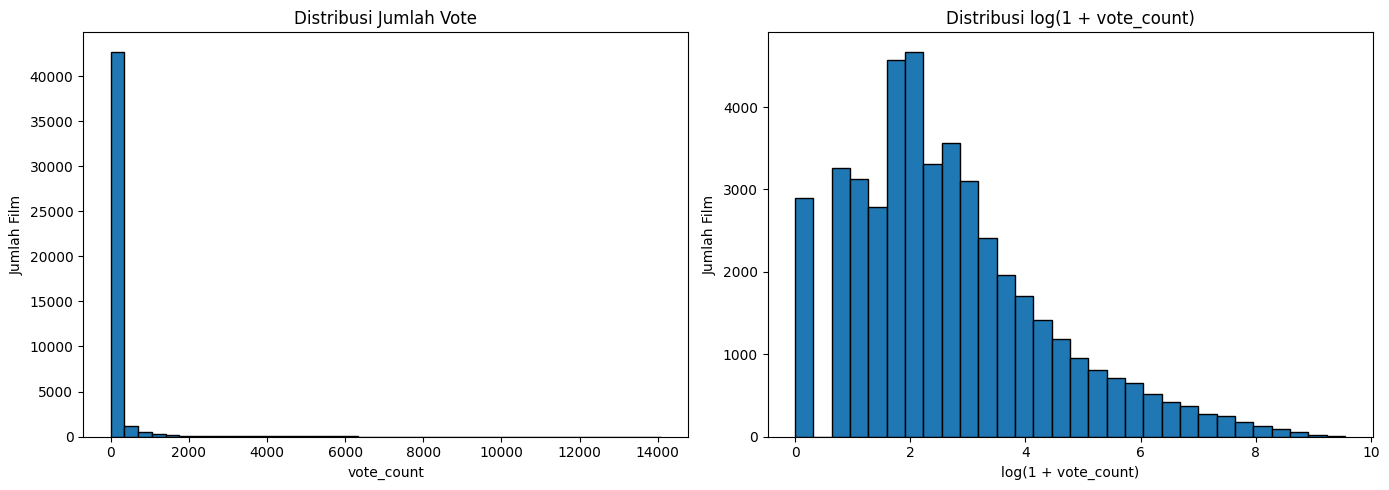

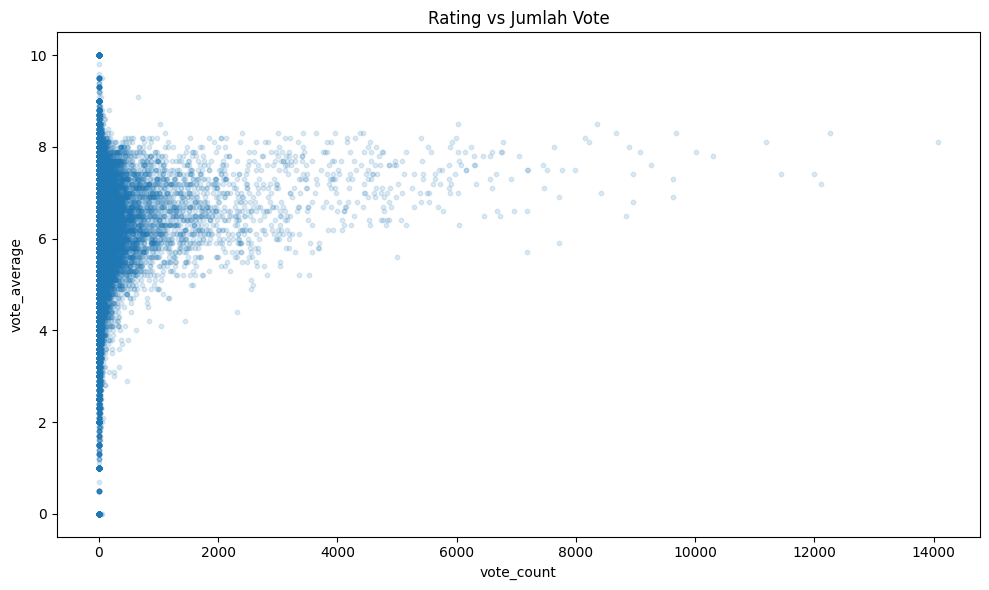

In [14]:
rating = df_gabungan["vote_average"]
jumlah_vote = df_gabungan["vote_count"]

print("===== STATISTIK DESKRIPTIF vote_average =====")
print(rating.describe())

print("\n===== STATISTIK DESKRIPTIF vote_count =====")
print(jumlah_vote.describe())

n_nol_vote = int((jumlah_vote == 0).sum())
n_rating_nol = int((rating == 0).sum())
n_keduanya = int(((jumlah_vote == 0) & (rating == 0)).sum())
n_rating_nol_ada_vote = int(((rating == 0) & (jumlah_vote > 0)).sum())

print(f"\nFilm dengan 0 vote             : {n_nol_vote}")
print(f"Film dengan rating 0           : {n_rating_nol}")
print(f"  di antaranya tanpa vote      : {n_keduanya}")
print(f"  tetapi punya vote            : {n_rating_nol_ada_vote}")
print("Korelasi Pearson rating vs jumlah vote:", rating.corr(jumlah_vote))

# Histogram rating
plt.figure(figsize=(10, 5))
plt.hist(rating.dropna(), bins=20, range=(0, 10), edgecolor="black")
plt.title("Distribusi Rating Film (vote_average)")
plt.xlabel("Rating (0–10)")
plt.ylabel("Jumlah Film")
plt.tight_layout()
plt.show()

# Histogram jumlah vote: skala biasa dan log(1 + vote_count)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(jumlah_vote.dropna(), bins=40, edgecolor="black")
axes[0].set_title("Distribusi Jumlah Vote")
axes[0].set_xlabel("vote_count")
axes[0].set_ylabel("Jumlah Film")

axes[1].hist(np.log1p(jumlah_vote.dropna()), bins=30, edgecolor="black")
axes[1].set_title("Distribusi log(1 + vote_count)")
axes[1].set_xlabel("log(1 + vote_count)")
axes[1].set_ylabel("Jumlah Film")
plt.tight_layout()
plt.show()

# Hubungan rating dan jumlah vote
plt.figure(figsize=(10, 6))
plt.scatter(jumlah_vote, rating, alpha=0.15, s=10)
plt.title("Rating vs Jumlah Vote")
plt.xlabel("vote_count")
plt.ylabel("vote_average")
plt.tight_layout()
plt.show()


## 15. Pemeriksaan setelah data dirapikan

Sebelum tahap akhir, data yang sudah dirapikan diperiksa ulang:

- apakah masih ada ID duplikat
- jumlah nilai kosong pada kolom penting
- jumlah film tanpa genre, kata kunci, atau sutradara (tetap disimpan)
- jumlah film tanpa poster, durasi, atau pemeran (tetap disimpan)

Overview kosong dihitung dengan fungsi `jumlah_teks_kosong`, karena `.isna()` hasilnya 0 setelah NaN diganti teks kosong. Pada tahap ini hasilnya harus 959 film.


In [15]:
print("Ukuran dataset :", df_gabungan.shape)
print("ID duplikat    :", int(df_gabungan["id"].duplicated().sum()))

kolom_penting = [
    "id",
    "title",
    "overview",
    "genres_list",
    "keywords_list",
    "director",
    "release_year",
    "poster_path",
    "runtime",
    "cast_list",
]

print("\nNilai kosong (NaN) pada kolom penting:")
print(df_gabungan[kolom_penting].isna().sum())
print(
    "Overview kosong (NaN/teks kosong/hanya spasi):",
    jumlah_teks_kosong(df_gabungan["overview"]),
)

print("\nFilm tanpa genre    :", int((df_gabungan["genres_list"].apply(len) == 0).sum()))
print("Film tanpa keyword  :", int((df_gabungan["keywords_list"].apply(len) == 0).sum()))
print("Film tanpa director :", int((df_gabungan["director"].apply(len) == 0).sum()))
print("Film tanpa poster   :", int(df_gabungan["poster_path"].isna().sum()))
print("Film tanpa durasi   :", int(df_gabungan["runtime"].isna().sum()))
print("Film tanpa pemeran  :", int((df_gabungan["cast_list"].fillna("").eq("")).sum()))


Ukuran dataset : (45433, 32)
ID duplikat    : 0

Nilai kosong (NaN) pada kolom penting:
id                  0
title               3
overview            0
genres_list         0
keywords_list       0
director            0
release_year       87
poster_path       386
runtime          1818
cast_list           0
dtype: int64
Overview kosong (NaN/teks kosong/hanya spasi): 959

Film tanpa genre    : 2442
Film tanpa keyword  : 14341
Film tanpa director : 888
Film tanpa poster   : 386
Film tanpa durasi   : 1818
Film tanpa pemeran  : 2415


## 16. Menghapus film tanpa judul

Ada 3 film dengan ID valid tetapi tanpa judul. Judul dibutuhkan untuk menampilkan hasil rekomendasi, jadi film ini dihapus. Ketiga film ini punya sinopsis, sehingga jumlah overview kosong tetap 959.


In [16]:
film_tanpa_judul = df_gabungan[df_gabungan["title"].isna()]
print("Jumlah film tanpa judul:", len(film_tanpa_judul))
display(
    film_tanpa_judul[
        ["id", "title", "release_date", "overview", "genres_list"]
    ]
)

df_gabungan = df_gabungan.dropna(subset=["title"]).copy()
df_gabungan = df_gabungan.reset_index(drop=True)

print("\nJumlah baris setelah pembersihan judul:", len(df_gabungan))
print("Judul kosong :", int(df_gabungan["title"].isna().sum()))
print("ID duplikat  :", int(df_gabungan["id"].duplicated().sum()))
print(
    "Overview kosong setelah judul dihapus:",
    jumlah_teks_kosong(df_gabungan["overview"]),
)
print(
    "Tahun rilis kosong:",
    int(df_gabungan["release_year"].isna().sum()),
)


Jumlah film tanpa judul: 3


,id,title,release_date,overview,genres_list
26973,82663,NaN,NaT,British soldiers force a recently captured IRA...,"[Action, Thriller, Drama]"
31626,122662,NaN,NaT,Third film of the Mardock Scramble series.,"[Animation, Science Fiction]"
38327,249260,NaN,NaT,A group of skiers are terrorized during spring...,"[TV Movie, Action, Horror, Science Fiction]"



Jumlah baris setelah pembersihan judul: 45430
Judul kosong : 0
ID duplikat  : 0
Overview kosong setelah judul dihapus: 959
Tahun rilis kosong: 84


## 17. Pemeriksaan kolom adult, status, dan film tanpa vote

Sel berikut menampilkan sebaran kolom `adult` dan `status`, serta jumlah film dengan 0 vote. Film dewasa (`adult=True`) dan film dengan `status` selain `Released` akan dibuang di sel berikutnya. Film dengan `status` kosong tetap disimpan.

Film dengan 0 vote tetap disimpan. Rating film ini 0, jadi di antarmuka sebaiknya ditampilkan sebagai "Belum ada rating", bukan "0,0".


In [17]:
print("===== SEBARAN NILAI adult =====")
print(df_gabungan["adult"].value_counts(dropna=False))

print("\n===== SEBARAN NILAI status =====")
print(df_gabungan["status"].value_counts(dropna=False))

n_dewasa = int(
    df_gabungan["adult"].astype(str).str.strip().str.lower().eq("true").sum()
)
status_bersih = df_gabungan["status"].astype("string").str.strip()
status_kosong = status_bersih.isna() | status_bersih.eq("")
n_status_kosong = int(status_kosong.sum())
n_belum_rilis = int((~status_kosong & status_bersih.ne("Released")).sum())
n_keduanya = int(
    (
        df_gabungan["adult"].astype(str).str.strip().str.lower().eq("true")
        & (~status_kosong & status_bersih.ne("Released"))
    ).sum()
)
n_nol_vote = int((df_gabungan["vote_count"] == 0).sum())

print(f"\nFilm dewasa (adult=True)                    : {n_dewasa}")
print(f"Film berstatus bukan Released (status terisi) : {n_belum_rilis}")
print(f"Film yang termasuk keduanya                   : {n_keduanya}")
print(f"Status kosong (akan tetap disimpan)           : {n_status_kosong}")
print(f"Film dengan 0 vote                            : {n_nol_vote}")


===== SEBARAN NILAI adult =====
adult
False    45421
True         9
Name: count, dtype: int64

===== SEBARAN NILAI status =====
status
Released           44985
Rumored              229
Post Production       98
NaN                   81
In Production         20
Planned               15
Canceled               2
Name: count, dtype: int64

Film dewasa (adult=True)                    : 9
Film berstatus bukan Released (status terisi) : 364
Film yang termasuk keduanya                   : 1
Status kosong (akan tetap disimpan)           : 81
Film dengan 0 vote                            : 2896


## 18. Membuang film dewasa dan film yang belum rilis

Tahap ini menghapus film yang tidak memenuhi kriteria dataset, yaitu:
- film dengan `adult=True`
- film yang `status`-nya terisi dan bukan `Released`

 Film dengan status kosong (NaN atau teks kosong) tetap disimpan. Setelah penyaringan, jumlah baris, overview kosong, dan film dengan 0 vote dihitung kembali untuk memastikan data sesuai sebelum disimpan ke CSV.




In [18]:
# Membuang film dewasa dan film yang belum rilis; status kosong tetap dipertahankan
jumlah_awal = len(df_gabungan)
adult_true = df_gabungan["adult"].astype(str).str.strip().str.lower().eq("true")
status_bersih = df_gabungan["status"].astype("string").str.strip()
status_kosong = status_bersih.isna() | status_bersih.eq("")
belum_rilis = ~status_kosong & status_bersih.ne("Released")

n_dewasa = int(adult_true.sum())
n_belum_rilis = int(belum_rilis.sum())
n_keduanya = int((adult_true & belum_rilis).sum())
n_status_kosong = int(status_kosong.sum())
n_dibuang = int((adult_true | belum_rilis).sum())

df_gabungan = df_gabungan[~adult_true & ~belum_rilis].copy()
df_gabungan = df_gabungan.reset_index(drop=True)

JUMLAH_BARIS_AKHIR = len(df_gabungan)
JUMLAH_OVERVIEW_KOSONG = jumlah_teks_kosong(df_gabungan["overview"])
JUMLAH_NOL_VOTE = int((df_gabungan["vote_count"] == 0).sum())

print("===== PENYARINGAN adult DAN status =====")
print("Jumlah baris sebelum disaring              :", jumlah_awal)
print("Film dewasa (adult=True)                   :", n_dewasa)
print("Film berstatus bukan Released              :", n_belum_rilis)
print("Film yang termasuk keduanya                :", n_keduanya)
print("Status kosong yang tetap disimpan          :", n_status_kosong)
print("Jumlah baris yang dibuang                  :", n_dibuang)
print("Jumlah baris sesudah disaring              :", JUMLAH_BARIS_AKHIR)
print("Overview kosong sesudah disaring           :", JUMLAH_OVERVIEW_KOSONG)
print("Film dengan 0 vote sesudah disaring        :", JUMLAH_NOL_VOTE)

assert n_dibuang == n_dewasa + n_belum_rilis - n_keduanya, (
    "Hitungan baris yang dibuang tidak konsisten."
)
assert JUMLAH_BARIS_AKHIR == jumlah_awal - n_dibuang, (
    "Jumlah baris sesudah disaring tidak sesuai hitungan."
)
print("\nPenyaringan adult dan status berhasil.")


===== PENYARINGAN adult DAN status =====
Jumlah baris sebelum disaring              : 45430
Film dewasa (adult=True)                   : 9
Film berstatus bukan Released              : 364
Film yang termasuk keduanya                : 1
Status kosong yang tetap disimpan          : 81
Jumlah baris yang dibuang                  : 372
Jumlah baris sesudah disaring              : 45058
Overview kosong sesudah disaring           : 940
Film dengan 0 vote sesudah disaring        : 2864

Penyaringan adult dan status berhasil.


## 19. Menyimpan dataset bersih

Dataset disimpan dengan 12 kolom sesuai urutan yang telah ditentukan, yaitu:
`id`, `title`, `overview`, `genres_list`, `keywords_list`, `director`, `release_year`, `vote_average`, `vote_count`, `poster_path`, `runtime`, `cast_list`.

Sembilan kolom pertama dipertahankan seperti sebelumnya (nama, isi, dan format), karena model rekomendasi membacanya berdasarkan nama. Tiga kolom baru (`poster_path`, `runtime`, `cast_list`) ditambahkan di paling kanan untuk keperluan tampilan sistem.

Daftar genre, kata kunci, dan pemeran diubah menjadi teks yang dipisah tanda `|` agar mudah dibaca di CSV dan bisa diimpor ke MySQL.

Sebelum disimpan, `release_year`, `vote_count`, dan `runtime` diubah menjadi bilangan bulat yang boleh kosong, agar sesuai skema MySQL dan tidak tertulis sebagai desimal seperti `1988.0` atau `152.0`. Spasi pada sinopsis juga dibersihkan, lalu sinopsis kosong disimpan sebagai nilai kosong. Hitungan baris dan overview kosong pada file CSV diperiksa terhadap angka yang dihitung setelah penyaringan. Path poster dan daftar pemeran yang kosong disimpan kosong, tidak ditulis sebagai `nan` atau `None`.


In [19]:
KOLOM_FINAL = [
    "id",
    "title",
    "overview",
    "genres_list",
    "keywords_list",
    "director",
    "release_year",
    "vote_average",
    "vote_count",
    "poster_path",
    "runtime",
    "cast_list",
]
KOLOM_LAMA = KOLOM_FINAL[:9]

df_final = df_gabungan[KOLOM_FINAL].copy()

for kolom in ["genres_list", "keywords_list", "director"]:
    df_final[kolom] = df_final[kolom].apply(
        lambda x: "|".join(x) if isinstance(x, list) else ""
    )

# Mengubah tahun rilis, jumlah vote, dan durasi menjadi bilangan bulat (boleh kosong)
df_final["release_year"] = df_final["release_year"].astype("Int64")
df_final["vote_count"] = df_final["vote_count"].astype("Int64")
df_final["runtime"] = df_final["runtime"].astype("Int64")

# Membersihkan spasi di awal/akhir sinopsis, lalu mengubah sinopsis kosong menjadi NaN
df_final["overview"] = df_final["overview"].str.strip().replace("", pd.NA)

# Path poster dan daftar pemeran yang kosong disimpan sebagai teks kosong, bukan "nan"
df_final["poster_path"] = df_final["poster_path"].astype("string").fillna("")
df_final["cast_list"] = df_final["cast_list"].astype("string").fillna("")

df_final.to_csv(CSV_OUTPUT, index=False)

print("Dataset berhasil disimpan ke:", CSV_OUTPUT.resolve())
print("Ukuran dataset:", df_final.shape)
display(df_final.head())

# ----- Validasi akhir -----
print("\n===== VALIDASI AKHIR =====")
print("Kolom sesuai kontrak      :", list(df_final.columns) == KOLOM_FINAL)
print("Kolom yang tersimpan      :", list(df_final.columns))
print("Jumlah baris              :", len(df_final))
print("ID unik                   :", df_final["id"].nunique())
print("ID duplikat               :", int(df_final["id"].duplicated().sum()))
print("Judul kosong              :", int(df_final["title"].isna().sum()))
print(
    "Overview kosong (NaN/teks kosong/hanya spasi):",
    jumlah_teks_kosong(df_final["overview"]),
)
print("Tahun rilis kosong        :", int(df_final["release_year"].isna().sum()))
print("Rating kosong             :", int(df_final["vote_average"].isna().sum()))
print("Jumlah vote kosong        :", int(df_final["vote_count"].isna().sum()))
print("Film yang punya poster    :", int((df_final["poster_path"].str.len() > 0).sum()))
print("Film yang punya durasi    :", int(df_final["runtime"].notna().sum()))
print("Film yang punya pemeran   :", int((df_final["cast_list"].str.len() > 0).sum()))
print("Film tanpa poster         :", int((df_final["poster_path"].str.len() == 0).sum()))
print("Film tanpa durasi         :", int(df_final["runtime"].isna().sum()))
print("Film tanpa pemeran        :", int((df_final["cast_list"].str.len() == 0).sum()))

assert list(df_final.columns) == KOLOM_FINAL, "Urutan/nama kolom tidak sesuai kontrak."
assert df_final["id"].duplicated().sum() == 0, "Masih ada ID duplikat."
assert df_final["title"].isna().sum() == 0, "Masih ada judul kosong."
assert len(df_final) == JUMLAH_BARIS_AKHIR, (
    "Jumlah baris akhir tidak sama dengan hasil penyaringan."
)
assert jumlah_teks_kosong(df_final["overview"]) == JUMLAH_OVERVIEW_KOSONG, (
    "Hitungan overview kosong tidak sama dengan hasil setelah penyaringan."
)
print("\nValidasi akhir berhasil.")

# Memeriksa ulang file CSV dari berkas, bukan dari memori
cek = pd.read_csv(
    CSV_OUTPUT,
    dtype={"release_year": "Int64", "vote_count": "Int64", "runtime": "Int64"},
)
print("\n===== PEMERIKSAAN ULANG CSV =====")
print("Kolom pada file            :", list(cek.columns))
print("Jumlah baris pada file     :", len(cek))
print("ID unik pada file          :", cek["id"].nunique())
print(
    "Overview kosong (NaN) saat CSV dibaca ulang:",
    int(cek["overview"].isna().sum()),
)
print("Film yang punya poster     :", int((cek["poster_path"].fillna("").str.len() > 0).sum()))
print("Film yang punya durasi     :", int(cek["runtime"].notna().sum()))
print("Film yang punya pemeran    :", int((cek["cast_list"].fillna("").str.len() > 0).sum()))

assert list(cek.columns) == KOLOM_FINAL, "Urutan/nama kolom pada file tidak sesuai kontrak."
assert len(cek) == len(df_final) == cek["id"].nunique() == JUMLAH_BARIS_AKHIR, (
    "Jumlah baris dan ID unik pada file tidak sama dengan hasil penyaringan."
)
assert int(cek["overview"].isna().sum()) == JUMLAH_OVERVIEW_KOSONG, (
    "Hitungan overview kosong pada CSV tidak sama dengan hasil setelah penyaringan."
)

# Cuplikan nilai mentah di file CSV (tanpa inferensi tipe pandas)
import csv as csv_modul

teks_terlarang = {"nan", "none", "NaN", "None", "NONE"}
kolom_bulat = ["release_year", "vote_count", "runtime"]
jumlah_teks_terlarang = 0
jumlah_desimal = 0
contoh_desimal = []

with Path(CSV_OUTPUT).open(encoding="utf-8", newline="") as f_csv:
    pembaca = csv_modul.DictReader(f_csv)
    assert list(pembaca.fieldnames) == KOLOM_FINAL, "Header CSV tidak sesuai kontrak."
    print("\nLima baris mentah release_year, vote_count, dan runtime pada CSV:")
    for i, baris in enumerate(pembaca):
        if i < 5:
            print(
                f"  release_year={baris['release_year']!r}  "
                f"vote_count={baris['vote_count']!r}  "
                f"runtime={baris['runtime']!r}"
            )
        for nilai in baris.values():
            if nilai in teks_terlarang:
                jumlah_teks_terlarang += 1
        for kolom in kolom_bulat:
            nilai = baris[kolom]
            if nilai and "." in nilai:
                jumlah_desimal += 1
                if len(contoh_desimal) < 5:
                    contoh_desimal.append((kolom, nilai))

print("Nilai tepat 'nan'/'None' pada file:", jumlah_teks_terlarang)
print("Angka bulat yang tertulis dengan '.0' :", jumlah_desimal)
if contoh_desimal:
    print("Contoh:", contoh_desimal)

assert jumlah_teks_terlarang == 0, "Masih ada teks 'nan' atau 'None' pada file CSV."
assert jumlah_desimal == 0, "Masih ada angka bulat berbentuk desimal seperti 1988.0 pada file CSV."

# Pemeriksaan manual beberapa film terkenal
id_contoh = [155, 862, 597, 27205]  # The Dark Knight, Toy Story, Titanic (1997), Inception
film_contoh = cek[cek["id"].isin(id_contoh)][
    ["id", "title", "release_year", "poster_path", "runtime", "cast_list"]
]
print("\n===== CONTOH FILM TERKENAL =====")
display(film_contoh)

print("Pemeriksaan ulang CSV berhasil.")


Dataset berhasil disimpan ke: D:\Projek\sistem-rekomendasi-film\data\processed\movies_clean_final.csv
Ukuran dataset: (45058, 12)


,id,title,overview,genres_list,keywords_list,director,release_year,vote_average,vote_count,poster_path,runtime,cast_list
0,2,Ariel,Taisto Kasurinen is a Finnish coal miner whose...,Drama|Crime,underdog|prison|factory worker|prisoner|helsin...,Aki Kaurismäki,1988,7.1,44,/gZCJZOn4l0Zj5hAxsMbxoS6CL0u.jpg,69,Turo Pajala::Taisto Olavi Kasurinen|Susanna Ha...
1,3,Shadows in Paradise,"An episode in the life of Nikander, a garbage ...",Drama|Comedy,salesclerk|helsinki|garbage|independent film,Aki Kaurismäki,1986,7.1,35,/7ad4iku8cYBuB08g9yAU7tHJik5.jpg,76,Matti Pellonpää::Nikander|Kati Outinen::Ilona ...
2,5,Four Rooms,It's Ted the Bellhop's first night on the job....,Crime|Comedy,hotel|new year's eve|witch|bet|hotel room|sper...,Allison Anders|Alexandre Rockwell|Robert Rodri...,1995,6.5,539,/eQs5hh9rxrk1m4xHsIz1w11Ngqb.jpg,98,Tim Roth::Ted the Bellhop|Antonio Banderas::Ma...
3,6,Judgment Night,"While racing to a boxing match, Frank, Mike, J...",Action|Thriller|Crime,chicago|drug dealer|boxing match|escape|one night,Stephen Hopkins,1993,6.4,79,/lNXmgUrP6h1nD53gkFh4WDzT6RZ.jpg,110,Emilio Estevez::Frank Wyatt|Cuba Gooding Jr.::...
4,11,Star Wars,Princess Leia is captured and held hostage by ...,Adventure|Action|Science Fiction,android|galaxy|hermit|death star|lightsaber|je...,George Lucas,1977,8.1,6778,/btTdmkgIvOi0FFip1sPuZI2oQG6.jpg,121,Mark Hamill::Luke Skywalker|Harrison Ford::Han...



===== VALIDASI AKHIR =====
Kolom sesuai kontrak      : True
Kolom yang tersimpan      : ['id', 'title', 'overview', 'genres_list', 'keywords_list', 'director', 'release_year', 'vote_average', 'vote_count', 'poster_path', 'runtime', 'cast_list']
Jumlah baris              : 45058
ID unik                   : 45058
ID duplikat               : 0
Judul kosong              : 0
Overview kosong (NaN/teks kosong/hanya spasi): 940
Tahun rilis kosong        : 79
Rating kosong             : 0
Jumlah vote kosong        : 0
Film yang punya poster    : 44678
Film yang punya durasi    : 43291
Film yang punya pemeran   : 42673
Film tanpa poster         : 380
Film tanpa durasi         : 1767
Film tanpa pemeran        : 2385

Validasi akhir berhasil.

===== PEMERIKSAAN ULANG CSV =====
Kolom pada file            : ['id', 'title', 'overview', 'genres_list', 'keywords_list', 'director', 'release_year', 'vote_average', 'vote_count', 'poster_path', 'runtime', 'cast_list']
Jumlah baris pada file     : 45058
ID

,id,title,release_year,poster_path,runtime,cast_list
112,155,The Dark Knight,2008,/1hRoyzDtpgMU7Dz4JF22RANzQO7.jpg,152,Christian Bale::Bruce Wayne / Batman|Michael C...
456,597,Titanic,1997,/kHXEpyfl6zqn8a6YuozZUujufXf.jpg,194,Kate Winslet::Rose DeWitt Bukater|Leonardo DiC...
682,862,Toy Story,1995,/rhIRbceoE9lR4veEXuwCC2wARtG.jpg,81,Tom Hanks::Woody (voice)|Tim Allen::Buzz Light...
11707,27205,Inception,2010,/qmDpIHrmpJINaRKAfWQfftjCdyi.jpg,148,Leonardo DiCaprio::Dom Cobb|Joseph Gordon-Levi...


Pemeriksaan ulang CSV berhasil.


## 20. Selesai

Notebook menghasilkan data/processed/movies_clean_final.csv yang berisi 45.058 film dan siap digunakan untuk model dan backend. Sebanyak 372 film dihapus, sedangkan 81 film dengan status kosong tetap disimpan. Sembilan kolom lama dipertahankan dengan format yang sama dan tiga kolom baru (poster_path, runtime, cast_list) ditambahkan untuk kebutuhan tampilan poster, durasi, dan pemeran.

Hasil akhir dataset terdiri dari 940 overview kosong, 2.864 film tanpa vote, 44.678 film dengan poster, 43.291 film dengan durasi, dan 42.673 film dengan pemeran


In [20]:
if Path(CSV_OUTPUT).exists():
    print("File hasil:", Path(CSV_OUTPUT).resolve())
    try:
        from google.colab import files

        files.download(str(CSV_OUTPUT))
    except ImportError:
        print("Bukan lingkungan Colab; file tidak diunduh otomatis.")
else:
    raise FileNotFoundError(f"{CSV_OUTPUT} belum dibuat. Jalankan sel penyimpanan lebih dulu.")


File hasil: D:\Projek\sistem-rekomendasi-film\data\processed\movies_clean_final.csv
Bukan lingkungan Colab; file tidak diunduh otomatis.


## 21. Pengujian opsional alamat poster

Sel ini mengecek apakah poster film masih bisa dibuka. Caranya dengan mengambil 10 film, lalu membuka alamat posternya, yaitu `https://image.tmdb.org/t/p/w500` ditambah isi kolom `poster_path`.

Datanya dari tahun 2017, jadi banyak poster yang sekarang sudah tidak bisa dibuka (muncul kode 404). Ini wajar, karena TMDB sudah mengganti banyak gambar posternya. Karena itu, di tampilan website perlu disiapkan pengganti, misalnya inisial judul film, jika posternya gagal muncul.

Sel ini tidak wajib dijalankan. Jika tidak ada internet, sel ini hanya menampilkan catatan dan tidak membuat **Run all** gagal.

In [21]:
# Pengujian opsional. Kegagalan jaringan tidak menghentikan Run All.
import urllib.error
import urllib.request

POSTER_BASE = "https://image.tmdb.org/t/p/w500"
TIMEOUT_DETIK = 8
JUMLAH_UJI = 10
ID_UTAMA = [155, 862, 597, 27205]  # The Dark Knight, Toy Story, Titanic, Inception

try:
    if not Path(CSV_OUTPUT).exists():
        raise FileNotFoundError(f"{CSV_OUTPUT} belum dibuat.")

    data_poster = pd.read_csv(CSV_OUTPUT, usecols=["id", "title", "poster_path"])
    data_poster["poster_path"] = data_poster["poster_path"].fillna("").astype(str).str.strip()
    data_poster = data_poster[data_poster["poster_path"].str.len() > 0]

    terpilih = data_poster[data_poster["id"].isin(ID_UTAMA)].copy()
    sisa = data_poster[~data_poster["id"].isin(terpilih["id"])].head(JUMLAH_UJI - len(terpilih))
    sampel = pd.concat([terpilih, sisa], ignore_index=True).head(JUMLAH_UJI)

    print(f"Menguji {len(sampel)} alamat poster (batas waktu {TIMEOUT_DETIK} detik per alamat).")
    berhasil = 0
    gagal = 0
    for _, film in sampel.iterrows():
        url = POSTER_BASE + film["poster_path"]
        try:
            permintaan = urllib.request.Request(url, method="GET")
            with urllib.request.urlopen(permintaan, timeout=TIMEOUT_DETIK) as jawaban:
                kode = jawaban.status
                jawaban.read(128)
            status = "berhasil" if 200 <= kode < 300 else f"gagal ({kode})"
            if 200 <= kode < 300:
                berhasil += 1
            else:
                gagal += 1
        except Exception as exc:  # noqa: BLE001 - jaringan tidak boleh menghentikan Run All
            status = f"gagal ({type(exc).__name__}: {exc})"
            gagal += 1
        print(f"- {film['title']}: {status}")
        print(f"  {url}")

    print(f"\nHasil: {berhasil} berhasil dibuka, {gagal} tidak tersedia atau gagal dihubungi.")
except Exception as exc:  # noqa: BLE001
    print(
        "Pengujian poster dilewati karena koneksi tidak tersedia atau berkas belum siap:",
        f"{type(exc).__name__}: {exc}",
    )


Menguji 10 alamat poster (batas waktu 8 detik per alamat).
- The Dark Knight: berhasil
  https://image.tmdb.org/t/p/w500/1hRoyzDtpgMU7Dz4JF22RANzQO7.jpg
- Titanic: gagal (HTTPError: HTTP Error 404: Not Found)
  https://image.tmdb.org/t/p/w500/kHXEpyfl6zqn8a6YuozZUujufXf.jpg
- Toy Story: gagal (HTTPError: HTTP Error 404: Not Found)
  https://image.tmdb.org/t/p/w500/rhIRbceoE9lR4veEXuwCC2wARtG.jpg
- Inception: gagal (HTTPError: HTTP Error 404: Not Found)
  https://image.tmdb.org/t/p/w500/qmDpIHrmpJINaRKAfWQfftjCdyi.jpg
- Ariel: gagal (HTTPError: HTTP Error 404: Not Found)
  https://image.tmdb.org/t/p/w500/gZCJZOn4l0Zj5hAxsMbxoS6CL0u.jpg
- Shadows in Paradise: gagal (HTTPError: HTTP Error 404: Not Found)
  https://image.tmdb.org/t/p/w500/7ad4iku8cYBuB08g9yAU7tHJik5.jpg
- Four Rooms: gagal (HTTPError: HTTP Error 404: Not Found)
  https://image.tmdb.org/t/p/w500/eQs5hh9rxrk1m4xHsIz1w11Ngqb.jpg
- Judgment Night: gagal (HTTPError: HTTP Error 404: Not Found)
  https://image.tmdb.org/t/p/w500/l